In [40]:
import pandas as pd

In [41]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [42]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [43]:
df.shape

(7043, 21)

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [45]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [46]:
df.duplicated().sum()

np.int64(0)

In [47]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [48]:
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

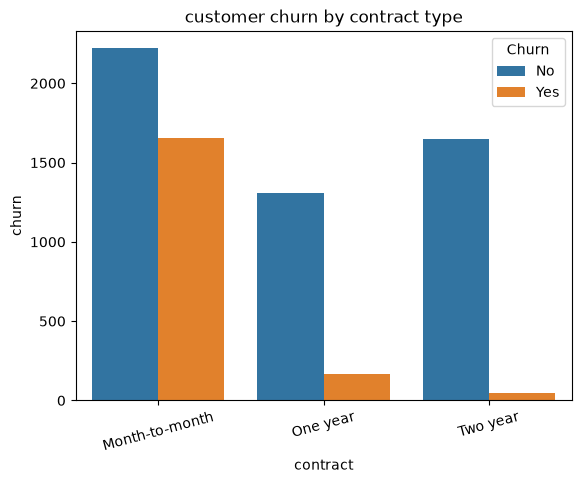

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data=df,x="Contract",hue="Churn")

plt.title("customer churn by contract type")
plt.xlabel("contract")
plt.ylabel("churn")
plt.xticks(rotation=15)
plt.tight_layout
plt.show()

In [50]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")
#df["TotalCharges"].dtype
df["TotalCharges"].isnull().sum()

np.int64(11)

In [51]:
X= df.drop(columns=["Churn","customerID"])
Y =df["Churn"]

In [52]:
print("features shape:", X.shape)
print("target shape:" ,Y.shape)

features shape: (7043, 19)
target shape: (7043,)


In [53]:
numerical_features=X.select_dtypes(
    include=["int64","float64"]).columns.tolist()

categorical_features=X.select_dtypes(include=['object','str','category']).columns.tolist()
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features) 

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer 
from sklearn.pipeline import Pipeline


In [55]:
numerical_transformer= Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

In [56]:
categorical_transformer= Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))

])

In [57]:
preprocessor= ColumnTransformer(transformers=[
    ("num",numerical_transformer,numerical_features),
    ("cat",categorical_transformer,categorical_features)
])

In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [59]:

# Step1:Import required libraries

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

import pandas as pd

# Ste 2: Define our machine learning models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

# Step3: Train and evaluate each model

results = []
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    yes_index = list(pipeline.classes_).index("Yes")
    y_prob = pipeline.predict_proba(X_test)[:, yes_index]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="Yes"),
        "Recall": recall_score(y_test, y_pred, pos_label="Yes"),
        "F1 Score": f1_score(y_test, y_pred, pos_label="Yes"),
        "ROC AUC": roc_auc_score(
            (y_test == "Yes").astype(int), y_prob
        )
    })

    trained_models[name] = pipeline

# Step4: Display comparison

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score", ascending=False
)

print("\nMODEL COMPARISON:")
display(results_df.round(4))


Training Logistic Regression...
Training Random Forest...
Training Gradient Boosting...

MODEL COMPARISON:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
2,Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
1,Random Forest,0.7637,0.5485,0.6203,0.5822,0.8225


Best model: Logistic Regression


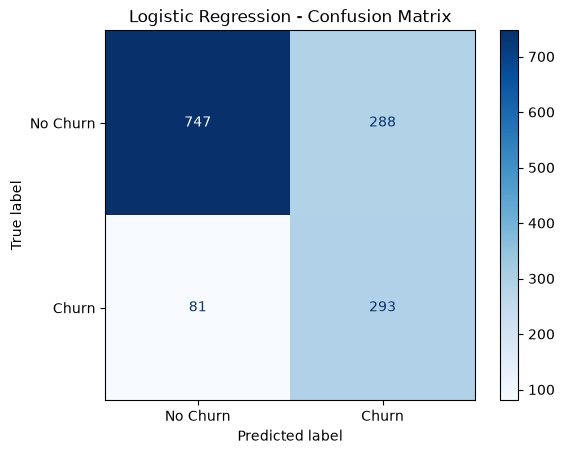

              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [60]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Select Logistic regress
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

# Make predictions
y_pred = best_model.predict(X_test)

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title(f"{best_model_name} - Confusion Matrix")
plt.show()

# Classification report
print(classification_report(y_test, y_pred))



In [61]:

# Save the best trained model

import joblib
import os

# Create models directory 
os.makedirs("../models", exist_ok=True)

# Save the complete pipeline
joblib.dump(
    best_model,
    "../models/churn_prediction_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!
